**Data Preprocessing Lecture: Used Cars Dataset**

Handling Column Formats & Missing Values

This lecture uses the structure of the well-known Kaggle "Used Cars Dataset", which typically has columns like:

Name, Location, Year, Kilometers_Driven, Fuel_Type, Transmission,
Owner_Type, Mileage, Engine, Power, Seats, New_Price, Price

First: Always Inspect Before You Touch Anything

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("used_cars_data.csv")

df.info()               # dtypes + non-null counts
df.head()
df.isnull().sum()       # missing values per column
df.isnull().mean()*100  # % missing per column
df.describe(include='all')
df.duplicated().sum()   # duplicate rows

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7253 entries, 0 to 7252
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   S.No.              7253 non-null   int64  
 1   Name               7253 non-null   object 
 2   Location           7253 non-null   object 
 3   Year               7253 non-null   int64  
 4   Kilometers_Driven  7253 non-null   int64  
 5   Fuel_Type          7253 non-null   object 
 6   Transmission       7253 non-null   object 
 7   Owner_Type         7253 non-null   object 
 8   Mileage            7251 non-null   object 
 9   Engine             7207 non-null   object 
 10  Power              7207 non-null   object 
 11  Seats              7200 non-null   float64
 12  New_Price          1006 non-null   object 
 13  Price              6019 non-null   float64
dtypes: float64(2), int64(3), object(9)
memory usage: 793.4+ KB


np.int64(0)

Why this matters:

you cannot decide how to fix a column until you know:

What dtype pandas thinks it is (often wrong — numbers stored as text)

How much is missing (5% missing ≠ 60% missing — different strategies)

Handling Column Formats (Before Missing Values)

Kaggle's used-cars data is notorious for storing numeric information as messy strings. You must clean formats before you impute, because mean()/median() can't be computed on a string column.

**Columns with embedded units (Mileage, Engine, Power)**

Raw values look like: "18.9 kmpl", "1197 CC", "78.9 bhp", sometimes with "null bhp" for missing.

In [ ]:
# Strip units and convert to numeric, coercing bad values to NaN
df['Mileage'] = df['Mileage'].str.replace(r'[^\d.]', '', regex=True)
df['Mileage'] = pd.to_numeric(df['Mileage'], errors='coerce')

df['Engine'] = df['Engine'].str.replace(' CC', '', regex=False)
df['Engine'] = pd.to_numeric(df['Engine'], errors='coerce')

df['Power'] = df['Power'].str.replace(' bhp', '', regex=False)
df['Power'] = pd.to_numeric(df['Power'], errors='coerce')   # "null bhp" -> NaN automatically

Selects the Mileage column.

Removes all characters except digits (0–9) and the decimal point (.) using a regular expression.

This cleans values like "18 kmpl" into "18" and "15.5 km/l" into "15.5".

The values are still strings after this step.

In [ ]:
df['Mileage'] = pd.to_numeric(df['Mileage'], errors='coerce')

Converts the cleaned string values into numeric data types (int or float).

If a value cannot be converted, errors='coerce' replaces it with NaN (missing value).

| Original Value | After `str.replace()` | After `to_numeric()` |
| -------------- | --------------------- | -------------------- |
| `18 kmpl`      | `"18"`                | `18`                 |
| `15.5 km/l`    | `"15.5"`              | `15.5`               |
| `Unknown`      | `""`                  | `NaN`                |


In [ ]:
df['New_Price'] = df['New_Price'].str.replace(' Lakh', '', regex=False)

**Standardizing categorical text**

In [ ]:
df['Fuel_Type'] = df['Fuel_Type'].str.strip().str.title()
df['Transmission'] = df['Transmission'].str.strip().str.title()
# Fix inconsistent labels, e.g. "petrol", "PETROL", "Petrol " -> "Petrol"

In [ ]:
print(df.head())

   S.No.                              Name    Location  Year  \
0      0            Maruti Wagon R LXI CNG      Mumbai  2010   
1      1  Hyundai Creta 1.6 CRDi SX Option        Pune  2015   
2      2                      Honda Jazz V     Chennai  2011   
3      3                 Maruti Ertiga VDI     Chennai  2012   
4      4   Audi A4 New 2.0 TDI Multitronic  Coimbatore  2013   

   Kilometers_Driven Fuel_Type Transmission Owner_Type  Mileage  Engine  \
0              72000       Cng       Manual      First    26.60   998.0   
1              41000    Diesel       Manual      First    19.67  1582.0   
2              46000    Petrol       Manual      First    18.20  1199.0   
3              87000    Diesel       Manual      First    20.77  1248.0   
4              40670    Diesel    Automatic     Second    15.20  1968.0   

    Power  Seats New_Price  Price  
0   58.16    5.0       NaN   1.75  
1  126.20    5.0       NaN  12.50  
2   88.70    5.0      8.61   4.50  
3   88.76    7.0    

**Handling Missing Values — The Core of This Lecture**

There is no single "correct" method — the right choice depends on:

Column type: numeric continuous, numeric discrete/count, categorical, ordinal, or derived (like Age)

% missing

Whether missingness itself is informative (e.g., missing New_Price because the car is old and no longer sold new — that's MNAR, not random!)

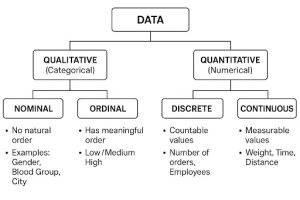

**Decision framework**

Situation	Recommended approach
< 5% missing, no obvious pattern	Simple imputation (mean/median/mode) is usually fine

5–30% missing	Group-wise imputation, KNN, or model-based imputation

40–50% missing	Consider dropping the column, or add a "missing" indicator + flag

Missingness is meaningful (MNAR-Missing not at Random)	Create a binary "was_missing" flag column, impute separately

Categorical with missing = a real category (e.g. no sunroof)	Fill with "None" / "Not Applicable", don't guess

**Numeric Continuous Columns (Mileage, Power, Price, Engine)**

1. Mean — for continuous numeric columns that are roughly symmetric
python

Use mean when the column doesn't have extreme outliers pulling the average in one direction.

In [ ]:
df['Mileage'] = df['Mileage'].fillna(df['Mileage'].mean())
df['Engine']  = df['Engine'].fillna(df['Engine'].mean())

2. Median — for continuous numeric columns that are skewed

In [ ]:
df['Price'] = df['Price'].fillna(df['Price'].median())
df['Kilometers_Driven'] = df['Kilometers_Driven'].fillna(df['Kilometers_Driven'].median())

Price and Kilometers_Driven almost always have a long right tail (a few very expensive/high-mileage cars), so mean gets distorted upward — median is the safer default here.

Quick rule: check skew before choosing:

In [ ]:
print(df['Mileage'].skew())   # close to 0 -> mean is fine
print(df['Price'].skew())     # far from 0 -> use median

3. Mode — for categorical / discrete columns

In [ ]:
df['Fuel_Type']    = df['Fuel_Type'].fillna(df['Fuel_Type'].mode()[0])
df['Transmission']  = df['Transmission'].fillna(df['Transmission'].mode()[0])
df['Owner_Type']    = df['Owner_Type'].fillna(df['Owner_Type'].mode()[0])
df['Seats']          = df['Seats'].fillna(df['Seats'].mode()[0])  # discrete/count column, not truly continuous

If Year itself has missing values, treat it as a normal numeric column — median is safest:

In [ ]:
df['Year'] = df['Year'].fillna(df['Year'].median())